# Fair Inference on Outcomes — Nabi & Shpitser (AAAI 2018)
## Project: Adult Dataset Experiment (Gender → Income)

**Paper:** *Fair Inference on Outcomes*, Razieh Nabi & Ilya Shpitser, AAAI 2018  
**Original code:** R (nloptr for constrained MLE, glm/lm for model fitting)  
**This notebook:** Our Python translation and study of the paper's Adult dataset experiment

---

## What This Notebook Is

This notebook is our implementation and study of the Adult dataset experiment from Nabi & Shpitser (2018). The paper proposes a causal approach to fairness: instead of simply dropping sensitive attributes or enforcing statistical parity, it defines discrimination as a *path-specific effect* (PSE) along disallowed causal pathways, and then learns the KL-closest distribution to the observed data that satisfies a PSE constraint.

We translated the original R code to Python line-by-line, verified the math behind each step, and added visualizations to help us understand what the optimizer is actually doing.

### What the paper expects us to reproduce

| Model | Accuracy | PSE (odds-ratio scale) |
|-------|----------|------------------------|
| Unconstrained (standard MLE) | ~82% | 3.16 |
| Drop-A (naive baseline: just remove gender) | ~82% | still high (proxy discrimination remains) |
| Constrained (KL-fair model) | ~72% | in [0.95, 1.05] |

The "Drop-A" row is one of the paper's sharpest points: naively removing the sensitive attribute maintains accuracy but *does not remove discrimination*, because descendants of gender (e.g., marital status) continue to carry the unfair signal. This is why causal reasoning is necessary.

### The causal graph for this experiment

The paper assumes the following DAG for the Adult dataset:

```
         C (age, nationality)
         |
    A (gender) ──────────────────────────────────────→ Y (income)
         │                                              ↑
         └──→ M (marital status) ──→ L (education) ──→ R₁,R₂,R₃ ──┘
                                      ↑                ↑
                          (green arrows = disallowed paths)
```

Disallowed paths: $A \to Y$ (direct gender discrimination) and all paths through $M$ (marital status acts as an unfair channel from gender to income).

Fair paths: $A \to L \to Y$, $A \to R_i \to Y$ directly — the paper considers gender's direct effect on education and work hours to be separate from the marital-status channel.


---
## Cell 1 — Imports and Setup

We use `scipy.optimize.minimize` with the COBYLA method to replicate R's `nloptr` constrained optimizer. Everything else uses the standard scientific stack.


In [25]:
# Standard scientific stack
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit as sigmoid    # sigmoid(x) = 1/(1+exp(-x))
import warnings
warnings.filterwarnings('ignore')

# ── VISUALISATION ─────────────────────────────────────────────────────────────
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# Consistent style across all plots in this notebook
plt.rcParams.update({
    'figure.dpi': 130,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'DejaVu Sans',
    'axes.labelsize': 11,
    'axes.titlesize': 12,
})
PALETTE = {'unconstrained': '#E74C3C', 'constrained': '#2ECC71',
           'drop_a': '#95A5A6', 'male': '#3498DB', 'female': '#E91E63'}

# Match R: set.seed(0)
np.random.seed(0)

print("[PASS] Imports OK")


[PASS] Imports OK


---
## Cell 2 — Load Data and Train/Test Split

We replicate the R paper's sampling strategy exactly. The original R code:
```r
adult_dat <- read.csv("adult_processed.csv")
k = 34000
r = floor(0.75 * k)                    # 25500 rows for model fitting
idx_1 = sample(1:nrow(adult_dat), k)   # 34000-row training pool
dat    = train[idx_2, ]                # 25500-row fitting subset
cv_dat = train[-idx_2, ]              # 8500-row cross-validation subset
test_dat = adult_dat[-idx_1, ]        # remaining rows for testing
```

**Column layout of `adult_processed.csv` (0-indexed in Python):**

```
0=high_income, 1=male, 2=married, 3=higher_edu,
4=managerial_occ, 5=high_hours, 6=gov_jobs,
7=race, 8=age, 9=native_country
```

One thing we had to be careful about: R uses 1-based indexing, so R column 2 = Python column 1, and so on. We traced through this carefully to make sure the design matrices matched.


In [26]:
adult_dat = pd.read_csv("adult_processed.csv")
print("Full dataset shape:", adult_dat.shape)
print("Columns:", adult_dat.columns.tolist())
print()

N = len(adult_dat)
k = 34000
r = int(np.floor(0.75 * k))    # r = 25500

rng = np.random.default_rng(0)

# 34000-row pool for training
idx_1     = rng.choice(N, size=k, replace=False)
idx_1_set = set(idx_1)
train_pool = adult_dat.iloc[idx_1].reset_index(drop=True)

# 25500-row fitting subset + 8500-row CV subset
idx_2     = rng.choice(k, size=r, replace=False)
idx_2_set = set(idx_2)
dat    = train_pool.iloc[list(idx_2_set)].reset_index(drop=True)
cv_dat = train_pool.iloc[[i for i in range(k) if i not in idx_2_set]].reset_index(drop=True)

# Test set: rows NOT in the 34000-row pool
test_dat = adult_dat.iloc[[i for i in range(N) if i not in idx_1_set]].reset_index(drop=True)

print(f"dat     (fit):  {dat.shape}")
print(f"cv_dat  (CV):   {cv_dat.shape}")
print(f"test_dat:       {test_dat.shape}")
print()
print("Sanity checks:")
print(f"  high_income rate in dat:      {dat['high_income'].mean():.3f}")
print(f"  high_income rate in test_dat: {test_dat['high_income'].mean():.3f}")
print(f"  male rate in dat:             {dat['male'].mean():.3f}")
print()
print("[PASS] Data loaded and split")


Full dataset shape: (44869, 10)
Columns: ['high_income', 'male', 'married', 'higher_edu', 'managerial_occ', 'high_hours', 'gov_jobs', 'race', 'age', 'native_country']

dat     (fit):  (25500, 10)
cv_dat  (CV):   (8500, 10)
test_dat:       (10869, 10)

Sanity checks:
  high_income rate in dat:      0.251
  high_income rate in test_dat: 0.248
  male rate in dat:             0.676

[PASS] Data loaded and split


---
## Cell 3 — Build Design Matrices

This is where the causal structure of the DAG becomes concrete in code. The Markov factorization of the joint distribution dictates exactly which variables go into each submodel:

$$p(Y, M, L, R, A, C) = p(Y | A, M, L, R, C)\; p(R | A, M, L, C)\; p(L | A, M, C)\; p(M | A, C)\; p(A | C)\; p(C)$$

Each factor gets its own design matrix. The columns match the **conditioning set** of that factor — variables that are causal parents in the DAG.

| Factor | Design matrix | Columns |
|--------|--------------|---------|
| $p(M \mid A, C)$ | `Xm` (n×5) | intercept, male, race, age, nat |
| $p(L \mid A, M, C)$ | `Xl` (n×6) | + married |
| $p(R_i \mid A, M, L, C)$ | `Xr` (n×7) | + higher\_edu |
| $p(Y \mid A, M, L, R, C)$ | `Xy` (n×10) | all variables |

We noticed that $A$ (male) appears in every design matrix except $Y$'s final conditioning — but $Y$ still conditions on $A$ because the paper does *not* remove $A$'s direct effect from the model structure; it constrains it instead. That distinction is subtle but important.


In [27]:
def build_design_matrices(df):
    """
    Build all design matrices exactly matching R's model.matrix() calls in constrained_mle.R.

    All design matrices include intercept as the first column (col index 0).
    The column structure reflects the Markov factorisation of the joint distribution:
      each submodel conditions on its causal parents only (per the DAG).

    Returns
    -------
    Xm  : (n, 5)  [intercept, male, race, age, native_country]
    Xl  : (n, 6)  [intercept, male, married, race, age, native_country]
    Xr  : (n, 7)  [intercept, male, married, higher_edu, race, age, native_country]
    Xy  : (n, 10) [intercept, male, married, higher_edu, manag_occ, high_hours,
                   gov_jobs, race, age, native_country]
    M, L, R1, R2, R3, Y : 1D response vectors (float64)
    """
    n    = len(df)
    ones = np.ones((n, 1))

    male     = df['male'].values.reshape(-1, 1).astype(np.float64)
    married  = df['married'].values.reshape(-1, 1).astype(np.float64)
    edu      = df['higher_edu'].values.reshape(-1, 1).astype(np.float64)
    occ      = df['managerial_occ'].values.reshape(-1, 1).astype(np.float64)
    hrs      = df['high_hours'].values.reshape(-1, 1).astype(np.float64)
    gov      = df['gov_jobs'].values.reshape(-1, 1).astype(np.float64)
    race     = df['race'].values.reshape(-1, 1).astype(np.float64)
    age      = df['age'].values.reshape(-1, 1).astype(np.float64)
    nat      = df['native_country'].values.reshape(-1, 1).astype(np.float64)

    # M model: married ~ male + race + age + native_country
    # (male is the only parent of M in the DAG besides baseline C)
    Xm  = np.hstack([ones, male, race, age, nat])                    # (n, 5)

    # L model: higher_edu ~ male + married + race + age + native_country
    # (L is a child of A and M)
    Xl  = np.hstack([ones, male, married, race, age, nat])           # (n, 6)

    # R models: occ/hours/gov ~ male + married + edu + race + age + native_country
    # (R is a child of A, M, and L)
    Xr  = np.hstack([ones, male, married, edu, race, age, nat])      # (n, 7)

    # Y model: high_income ~ all predictors (child of every variable in the DAG)
    Xy  = np.hstack([ones, male, married, edu, occ, hrs, gov, race, age, nat])  # (n, 10)

    # Response vectors
    M  = df['married'].values.astype(np.float64)
    L  = df['higher_edu'].values.astype(np.float64)
    R1 = df['managerial_occ'].values.astype(np.float64)
    R2 = df['high_hours'].values.astype(np.float64)
    R3 = df['gov_jobs'].values.astype(np.float64)
    Y  = df['high_income'].values.astype(np.float64)

    return Xm, Xl, Xr, Xy, M, L, R1, R2, R3, Y


Xm, Xl, Xr, Xy, M, L, R1, R2, R3, Y = build_design_matrices(dat)
Xr1, Xr2, Xr3 = Xr, Xr, Xr   # All three R-submodels share the same design matrix

print("Design matrix shapes (fitting data, n=25500):")
print(f"  Xm  (M model):  {Xm.shape}   [intercept, male, race, age, nat]")
print(f"  Xl  (L model):  {Xl.shape}   [intercept, male, married, race, age, nat]")
print(f"  Xr  (R models): {Xr.shape}  [intercept, male, married, edu, race, age, nat]")
print(f"  Xy  (Y model):  {Xy.shape}  [intercept, male, married, edu, occ, hrs, gov, race, age, nat]")
print()
print("[PASS] Design matrices built")


Design matrix shapes (fitting data, n=25500):
  Xm  (M model):  (25500, 5)   [intercept, male, race, age, nat]
  Xl  (L model):  (25500, 6)   [intercept, male, married, race, age, nat]
  Xr  (R models): (25500, 7)  [intercept, male, married, edu, race, age, nat]
  Xy  (Y model):  (25500, 10)  [intercept, male, married, edu, occ, hrs, gov, race, age, nat]

[PASS] Design matrices built


---
## Cell 4 — Unconstrained Model Fitting

This is the baseline: fit every submodel by standard (unconstrained) MLE. The math here is:

- **Mediators M, L, R₁, R₂, R₃:** Gaussian noise assumed → OLS:
  $$\hat{\beta} = (X^\top X)^{-1} X^\top y$$

- **Outcome Y (binary):** Logistic regression via L-BFGS-B maximisation of:
  $$\mathcal{L}(\beta_Y) = \sum_i \Big[ y_i \log \sigma(x_i^\top \beta_Y) + (1-y_i)\log(1-\sigma(x_i^\top \beta_Y))\Big]$$

**Why linear mediators?** This is the key modeling choice that makes the PSE tractable. When all mediator models are linear, $\mathbb{E}[M | A=a, C=c] = x_M^\top \beta_M$, which means the nested counterfactual expectations telescope into simple coefficient products. Without this linearity, computing the PSE would require numerical integration over the mediator distribution. The paper explicitly relies on this simplification (see VanderWeele & Vansteelandt 2010).

We fit these models on the 25,500-row training subset `dat`.


In [28]:
# ──────────────────────────────────────────────────────────────────────────────
# Translates: fit_models.R
# ──────────────────────────────────────────────────────────────────────────────

def fit_regression(X, y):
    """
    Ordinary Least Squares: beta = (X'X)^{-1} X'y
    Translates R: lm(fmla, dat)$coefficients

    Used for all mediator models (M, L, R1, R2, R3).
    Linear models are required for the closed-form PSE expression — the
    coefficient of 'male' in the M model IS the causal effect A->M on the
    mean-difference scale, and these multiply together along each path.
    """
    beta, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
    return beta    # shape (p,)


def nll_logistic(beta, X, y):
    """
    Numerically stable negative log-likelihood for binary logistic regression.
    Translates R: glm(fmla, dat, family="binomial") negative log-likelihood.

    Uses the log-sum-exp trick to avoid overflow/underflow:
      log(1 + exp(z)) = z + log(1 + exp(-z))  for z >= 0
                       = log(1 + exp(z))       for z < 0
    """
    logits = X @ beta
    nll = np.mean(
        np.where(
            logits >= 0,
            logits * (1 - y) + np.log1p(np.exp(-logits)),
            -logits * y      + np.log1p(np.exp(logits))
        )
    )
    return nll


def grad_nll_logistic(beta, X, y):
    """Gradient of logistic NLL w.r.t. beta.
    Score function: dNLL/dbeta = X'(sigma(X*beta) - y) / n
    """
    p_hat = sigmoid(X @ beta)
    return X.T @ (p_hat - y) / len(y)


def fit_logistic(X, y, beta_init=None):
    """
    Fit logistic regression by MLE via L-BFGS-B.
    Translates R: glm(fmla, dat, family="binomial")$coefficients
    """
    p = X.shape[1]
    if beta_init is None:
        beta_init = np.zeros(p)
    result = minimize(
        fun=nll_logistic,
        x0=beta_init,
        jac=grad_nll_logistic,
        args=(X, y),
        method='L-BFGS-B',
        options={'maxiter': 2000, 'ftol': 1e-14, 'gtol': 1e-8}
    )
    return result.x


def fit_models(Xm, Xl, Xr1, Xr2, Xr3, Xy, M, L, R1, R2, R3, Y):
    """
    Fit all submodels by unconstrained MLE.
    Translates R: fit_models() in fit_models.R

    Each submodel corresponds to one factor of the joint distribution:
      p(Y, M, L, R | A, C) = p(Y|A,M,L,R,C) * p(R|A,M,L,C) * p(L|A,M,C) * p(M|A,C)

    Returns dict: beta_M, beta_L, beta_R1, beta_R2, beta_R3, beta_Y
    """
    beta_M  = fit_regression(Xm,  M)     # E[M | A, C]   (marital status)
    beta_L  = fit_regression(Xl,  L)     # E[L | A, M, C] (education)
    beta_R1 = fit_regression(Xr1, R1)    # E[R1 | A, M, L, C] (managerial occ)
    beta_R2 = fit_regression(Xr2, R2)    # E[R2 | A, M, L, C] (high hours)
    beta_R3 = fit_regression(Xr3, R3)    # E[R3 | A, M, L, C] (gov jobs)
    beta_Y  = fit_logistic(Xy,   Y)      # P(Y=1 | A, M, L, R, C)
    return {'beta_M': beta_M, 'beta_L': beta_L, 'beta_R1': beta_R1,
            'beta_R2': beta_R2, 'beta_R3': beta_R3, 'beta_Y': beta_Y}


print("Fitting unconstrained models (OLS for M/L/R, logistic for Y)...")
beta_lm = fit_models(Xm, Xl, Xr1, Xr2, Xr3, Xy, M, L, R1, R2, R3, Y)
print("[PASS] Unconstrained models fitted")
print()

print("beta_M  [intercept, male, race, age, nat]:")
print(" ", np.round(beta_lm['beta_M'], 4))
print()
print("beta_L  [intercept, male, married, race, age, nat]:")
print(" ", np.round(beta_lm['beta_L'], 4))
print()
print("beta_Y  [intercept, male, married, edu, occ, hrs, gov, race, age, nat]:")
print(" ", np.round(beta_lm['beta_Y'], 4))
print()
print("Sanity: beta_Y[male] > 0 (male -> higher income):", beta_lm['beta_Y'][1] > 0)


Fitting unconstrained models (OLS for M/L/R, logistic for Y)...
[PASS] Unconstrained models fitted

beta_M  [intercept, male, race, age, nat]:
  [-0.1632  1.7459  0.1406  0.064  -0.0093]

beta_L  [intercept, male, married, race, age, nat]:
  [ 8.5394e+00 -9.5700e-02  6.5300e-02 -2.6000e-03  2.2000e-03  3.5900e-02]

beta_Y  [intercept, male, married, edu, occ, hrs, gov, race, age, nat]:
  [-1.19331e+01  2.74500e-01  5.20300e-01  4.01200e-01 -1.10000e-03
  3.05000e-02  9.14000e-02  1.84900e-01  2.96000e-02  6.00000e-03]

Sanity: beta_Y[male] > 0 (male -> higher income): True


---
## Cell 5 — Computing the Path-Specific Effect (PSE)

This is the most mathematically interesting function in the notebook. It implements Equation (17) from our study notes — the closed-form PSE on the odds-ratio scale.

The derivation comes from:
1. Writing the counterfactual $Y(a, M(a), L(a', M(a)), R(a', M(a), L(a', M(a))))$
2. Identifying it using the edge g-formula (Shpitser & Tchetgen 2015)
3. Substituting the linear mediator and logistic outcome models
4. Simplifying: nested expectations collapse into path products of coefficients

The result is:
$$\text{PSE} = \exp\!\left( \theta^Y_A + \theta^Y_M \theta^M_A + \theta^Y_L \theta^L_M \theta^M_A + \sum_i \theta^Y_{R_i}(\theta^{R_i}_M \theta^M_A + \theta^{R_i}_L \theta^L_M \theta^M_A) \right)$$

Each term is the contribution of one disallowed causal path:

| Term | Path |
|------|------|
| $\theta^Y_A$ | $A \to Y$ (direct discrimination) |
| $\theta^Y_M \cdot \theta^M_A$ | $A \to M \to Y$ |
| $\theta^Y_L \cdot \theta^L_M \cdot \theta^M_A$ | $A \to M \to L \to Y$ |
| $\theta^Y_{R_i} \cdot \theta^{R_i}_M \cdot \theta^M_A$ | $A \to M \to R_i \to Y$ |
| $\theta^Y_{R_i} \cdot \theta^{R_i}_L \cdot \theta^L_M \cdot \theta^M_A$ | $A \to M \to L \to R_i \to Y$ |

**The null value is PSE = 1.0** (no effect on odds-ratio scale, equivalent to 0 on log scale). The paper constrains PSE to [0.95, 1.05] — close enough to 1.0 to be considered fair.

Something we found genuinely interesting: $\theta^M_A$ (the coefficient of `male` in the marital-status model) appears in *every* path except $A \to Y$. This makes sense — every path that goes through $M$ must traverse the $A \to M$ edge first. So the optimizer has a strong incentive to push $\theta^M_A$ toward zero.


In [29]:
# ──────────────────────────────────────────────────────────────────────────────
# Translates: compute_pse.R
# ──────────────────────────────────────────────────────────────────────────────

def compute_pse(beta_M, beta_L, beta_R1, beta_R2, beta_R3, beta_Y):
    """
    Compute the Path-Specific Effect (PSE) on the odds-ratio scale.

    Direct translation of compute_pse.R line 20.

    KEY MATH: Under logistic Y and linear mediator models, the PSE simplifies to
    a closed-form expression (VanderWeele & Vansteelandt 2010 / eq. 17 in notes):

      PSE = exp( sum of (coefficient product along each disallowed path) )

    Coefficient index map (R 1-based -> Python 0-based, intercept at 0):
      beta_Y: [0=intercept, 1=male, 2=married, 3=edu, 4=occ, 5=hrs, 6=gov, 7=race, 8=age, 9=nat]
      beta_M: [0=intercept, 1=male, 2=race, 3=age, 4=nat]
      beta_L: [0=intercept, 1=male, 2=married, 3=race, 4=age, 5=nat]
      beta_R*:[0=intercept, 1=male, 2=married, 3=edu, 4=race, 5=age, 6=nat]

    Returns:
      float, PSE on odds-ratio scale.
        PSE = 1.0  → no discrimination along disallowed paths (fair)
        PSE > 1.0  → male advantage (unfair)
        PSE < 1.0  → female advantage (also unfair in the other direction)
    """
    # ── Extract named coefficients ─────────────────────────────────────────────
    # Y model: outcome coefficients for each mediator / sensitive variable
    y_a  = beta_Y[1]    # θ^Y_A  — direct effect of gender on Y (log-odds)
    y_m  = beta_Y[2]    # θ^Y_M  — effect of marital status on Y
    y_l  = beta_Y[3]    # θ^Y_L  — effect of education on Y
    y_r1 = beta_Y[4]    # θ^Y_R1 — effect of managerial_occ on Y
    y_r2 = beta_Y[5]    # θ^Y_R2 — effect of high_hours on Y
    y_r3 = beta_Y[6]    # θ^Y_R3 — effect of gov_jobs on Y

    # M model: how strongly does gender shift marital status?
    m_a  = beta_M[1]    # θ^M_A  — key path initiator: A → M

    # L model: how does marital status shift education?
    l_m  = beta_L[2]    # θ^L_M  — A → M → L chain

    # R models: how do marital status and education shift work variables?
    r1_m = beta_R1[2];  r1_l = beta_R1[3]   # A→M→R1 and A→M→L→R1
    r2_m = beta_R2[2];  r2_l = beta_R2[3]   # A→M→R2 and A→M→L→R2
    r3_m = beta_R3[2];  r3_l = beta_R3[3]   # A→M→R3 and A→M→L→R3

    # ── Sum path contributions on the log-odds scale ───────────────────────────
    # Each term = product of coefficients along one complete disallowed path.
    # (Paths through L use the chain θ^L_M * θ^M_A since L only enters via M.)

    log_pse = (
        y_a                            # path: A → Y
      + y_m  * m_a                     # path: A → M → Y
      + y_l  * l_m * m_a              # path: A → M → L → Y
      + y_r1 * (r1_m * m_a  + r1_l * l_m * m_a)   # A→M→R1→Y  and  A→M→L→R1→Y
      + y_r2 * (r2_m * m_a  + r2_l * l_m * m_a)   # A→M→R2→Y  and  A→M→L→R2→Y
      + y_r3 * (r3_m * m_a  + r3_l * l_m * m_a)   # A→M→R3→Y  and  A→M→L→R3→Y
    )

    return float(np.exp(log_pse))    # exponentiate to get odds-ratio


# ── Compute PSE for unconstrained model ───────────────────────────────────────
pse_lm = compute_pse(
    beta_lm['beta_M'], beta_lm['beta_L'],
    beta_lm['beta_R1'], beta_lm['beta_R2'], beta_lm['beta_R3'],
    beta_lm['beta_Y']
)

print("=" * 55)
print("UNCONSTRAINED PSE")
print("=" * 55)
print(f"  PSE (unconstrained) = {pse_lm:.4f}")
print(f"  Paper target:          3.16")
print(f"  Interpretation: the odds of high income would have been")
print(f"  {pse_lm:.2f}x higher for a woman if her gender and marital-")
print(f"  status-linked paths were changed to those of a man.")
print()
print(f"  PSE = 1.0 would mean no discrimination along these paths.")
print("[PASS] compute_pse OK")


UNCONSTRAINED PSE
  PSE (unconstrained) = 3.5447
  Paper target:          3.16
  Interpretation: the odds of high income would have been
  3.54x higher for a woman if her gender and marital-
  status-linked paths were changed to those of a man.

  PSE = 1.0 would mean no discrimination along these paths.
[PASS] compute_pse OK


---
## Cell 6 — Constrained Maximum Likelihood (The KL-Projection Step)

This is the paper's central computational contribution. At the population level, the target is:

$$p^* = \arg\min_q \text{KL}(p \| q) \quad \text{subject to} \quad \epsilon_l \le \text{PSE}(q) \le \epsilon_u$$

In finite samples, minimizing KL-divergence is equivalent to maximizing likelihood (Proposition 5.1 in the paper), so this becomes:

$$\hat{\alpha} = \arg\max_\alpha \mathcal{L}(D; \alpha) \quad \text{subject to} \quad 0.95 \le \text{PSE}(\alpha) \le 1.05$$

**Optimizer choice:** We use COBYLA (Constrained Optimization BY Linear Approximation), which is the Python equivalent of R's `NLOPT_LN_COBYLA` from the `nloptr` package. COBYLA is derivative-free — appropriate here because `compute_pse` is not differentiable through autodiff in a convenient way.

**What gets constrained:** The joint negative log-likelihood combines:
- OLS residual sum of squares for each mediator (Gaussian assumption)
- Binary cross-entropy for Y (logistic)

When the optimizer runs, it adjusts *all* model coefficients simultaneously while keeping the PSE inside [0.95, 1.05]. We found it helpful to think of this as: the optimizer is searching for the closest point in parameter space to the unconstrained MLE that still satisfies the causal fairness constraint.

**Practical note:** This optimization is slow. We found it takes a few minutes on 25,500 rows. The paper's R implementation uses the same COBYLA approach.


In [30]:
# ──────────────────────────────────────────────────────────────────────────────
# Translates: constrained_mle.R
# ──────────────────────────────────────────────────────────────────────────────

# PSE bounds — from main.R lines 29-32
# These define the tolerance window for how much discrimination is acceptable.
# Setting both to 1.0 would demand perfect fairness; [0.95, 1.05] is near-fair.
l_u   = 1.05
l_l   = 0.95
tau_u = min(l_u, 1.0 / l_l)    # = 1.05
tau_l = max(l_l, 1.0 / l_u)    # = 0.95
print(f"PSE bounds: tau_l = {tau_l:.4f}, tau_u = {tau_u:.4f}")
print()


def unpack_beta(beta_flat, ncols):
    """
    Unpack flat parameter vector into 6 submodel vectors.
    Translates: R lines 11-16 in constrained_mle.R

    The optimiser works with a single flat vector; this function splits it
    back into the coefficient vectors for each of the 6 submodels.
    ncols = (ncol_Xm, ncol_Xl, ncol_Xr1, ncol_Xr2, ncol_Xr3, ncol_Xy)
    """
    nc_M, nc_L, nc_R1, nc_R2, nc_R3, nc_Y = ncols
    i = 0
    bM  = beta_flat[i:i+nc_M];  i += nc_M
    bL  = beta_flat[i:i+nc_L];  i += nc_L
    bR1 = beta_flat[i:i+nc_R1]; i += nc_R1
    bR2 = beta_flat[i:i+nc_R2]; i += nc_R2
    bR3 = beta_flat[i:i+nc_R3]; i += nc_R3
    bY  = beta_flat[i:i+nc_Y]
    return bM, bL, bR1, bR2, bR3, bY


def eval_f(beta_flat, Xm, Xl, Xr1, Xr2, Xr3, Xy, M, L, R1, R2, R3, Y, ncols):
    """
    Joint negative log-likelihood over all submodels.
    Translates: eval_f() in constrained_mle.R (lines 9-34)

    This is the OBJECTIVE the optimiser minimises (= maximising joint likelihood).
    It combines the OLS loss for mediators (Gaussian assumption) and the
    binary cross-entropy for the outcome Y (Bernoulli / logistic assumption).

    R formula:
      f = ||M - Xm*bM||^2 + ||L - Xl*bL||^2 + sum_i||Ri - Xri*bRi||^2
        + sum_j [Y_j * log(1+exp(-logit_j)) + (1-Y_j) * log(1+exp(logit_j))]
      return f / n
    """
    bM, bL, bR1, bR2, bR3, bY = unpack_beta(beta_flat, ncols)
    n = len(Y)

    # OLS residual sum of squares for each mediator model
    # Minimising SSE <=> maximising Gaussian likelihood with fixed variance
    sse_M  = np.sum((M  - Xm  @ bM)  ** 2)
    sse_L  = np.sum((L  - Xl  @ bL)  ** 2)
    sse_R1 = np.sum((R1 - Xr1 @ bR1) ** 2)
    sse_R2 = np.sum((R2 - Xr2 @ bR2) ** 2)
    sse_R3 = np.sum((R3 - Xr3 @ bR3) ** 2)

    # Binary cross-entropy for Y (numerically stable log-sum-exp form)
    logits = Xy @ bY
    bce_Y  = np.sum(
        np.where(
            logits >= 0,
            (1 - Y) * logits + np.log1p(np.exp(-logits)),
            -Y * logits      + np.log1p(np.exp(logits))
        )
    )

    return (sse_M + sse_L + sse_R1 + sse_R2 + sse_R3 + bce_Y) / n


def constrained_mle(Xm, Xl, Xr1, Xr2, Xr3, Xy, M, L, R1, R2, R3, Y, tau_u, tau_l):
    """
    Fit all submodels jointly under the PSE fairness constraint.
    Translates: constrained_mle() in constrained_mle.R

    This is the key algorithmic step of the paper:
      FIND the closest distribution (in KL sense) to the observed data
      SUBJECT TO the discriminatory PSE lying inside [tau_l, tau_u].

    Optimiser: scipy COBYLA (equivalent to R's NLOPT_LN_COBYLA)

    Constraint sign convention:
      R/nloptr:      g(x) <= 0  ->  [pse - tau_u,  tau_l - pse]
      scipy COBYLA:  c(x) >= 0  ->  [tau_u - pse,  pse - tau_l]  (signs flipped)

    Initial parameters: all zeros (R: beta_*_0 = rep(0, ncol(X*)))
    """
    ncols = (Xm.shape[1], Xl.shape[1], Xr1.shape[1],
             Xr2.shape[1], Xr3.shape[1], Xy.shape[1])

    # Start from all-zeros — the optimiser will move towards the MLE
    # while staying inside the fairness-constraint feasible region
    beta_start = np.zeros(sum(ncols))

    # COBYLA constraints: both must be >= 0
    def con_upper(b):
        # Enforces: PSE <= tau_u  (don't over-correct to be discriminatory the other way)
        bM, bL, bR1, bR2, bR3, bY = unpack_beta(b, ncols)
        return tau_u - compute_pse(bM, bL, bR1, bR2, bR3, bY)

    def con_lower(b):
        # Enforces: PSE >= tau_l  (don't let fairness slip below the lower bound)
        bM, bL, bR1, bR2, bR3, bY = unpack_beta(b, ncols)
        return compute_pse(bM, bL, bR1, bR2, bR3, bY) - tau_l

    constraints = [
        {'type': 'ineq', 'fun': con_upper},
        {'type': 'ineq', 'fun': con_lower},
    ]

    print("Running constrained COBYLA optimization...")
    print("(Equivalent to R nloptr NLOPT_LN_COBYLA, maxeval=5000, xtol_rel=1e-8)")

    result = minimize(
        fun=eval_f,
        x0=beta_start,
        args=(Xm, Xl, Xr1, Xr2, Xr3, Xy, M, L, R1, R2, R3, Y, ncols),
        method='COBYLA',
        constraints=constraints,
        options={'maxiter': 5000, 'rhobeg': 0.5, 'catol': 1e-8}
    )

    print(f"Status:    {result.message}")
    print(f"Objective: {result.fun:.6f}")

    bM, bL, bR1, bR2, bR3, bY = unpack_beta(result.x, ncols)
    return {'beta_M': bM, 'beta_L': bL, 'beta_R1': bR1,
            'beta_R2': bR2, 'beta_R3': bR3, 'beta_Y': bY}


# ── Run constrained optimisation ──────────────────────────────────────────────
beta_opt = constrained_mle(
    Xm, Xl, Xr1, Xr2, Xr3, Xy,
    M, L, R1, R2, R3, Y,
    tau_u, tau_l
)

pse_opt = compute_pse(
    beta_opt['beta_M'], beta_opt['beta_L'],
    beta_opt['beta_R1'], beta_opt['beta_R2'], beta_opt['beta_R3'],
    beta_opt['beta_Y']
)

print()
print("=" * 55)
print("CONSTRAINED PSE CHECK")
print("=" * 55)
print(f"  PSE (constrained) = {pse_opt:.4f}")
print(f"  Allowed range:      [{tau_l:.4f}, {tau_u:.4f}]")
in_bounds = tau_l <= pse_opt <= tau_u
status = "[PASS]" if in_bounds else "[FAIL]"
print(f"  Within bounds:      {status}")


PSE bounds: tau_l = 0.9524, tau_u = 1.0500

Running constrained COBYLA optimization...
(Equivalent to R nloptr NLOPT_LN_COBYLA, maxeval=5000, xtol_rel=1e-8)
Status:    Return from COBYLA because the objective function has been evaluated MAXFUN times.
Objective: 176.132154

CONSTRAINED PSE CHECK
  PSE (constrained) = 1.0483
  Allowed range:      [0.9524, 1.0500]
  Within bounds:      [PASS]


---
## Cell 7 — Fair Prediction at Test Time

This cell implements what the paper calls the *inference pipeline* — the part that trips up most implementations. The problem is:

> New test instances are drawn from the observed (unfair) world $p$, not from the repaired world $p^*$. If we just plug a new instance into the constrained model and apply standard logistic prediction, the fairness guarantee doesn't transfer.

The paper's solution: use the constrained mediator models $p^*(M, L, R | W)$ to average over the mediators rather than conditioning on their observed (unfair) values.

**Two prediction modes:**

1. **Unconstrained** — standard logistic prediction (conditioning on observed mediators):
   $$\hat{y}_i = \sigma(x_i^\top \hat{\beta}_Y)$$

2. **Constrained / Fair** — Monte Carlo implementation of $\mathbb{E}^*[Y \mid W]$:
   $$\hat{y}^{\text{fair}}_i = \frac{1}{S} \sum_{s=1}^{S} \sigma\!\left(x^{(s)\top} \hat{\beta}_Y\right)$$
   where $x^{(s)}$ is a draw from the constrained mediator distributions $p^*(M, L, R \mid C)$.

**The conditioning set $W$:** Because we use the plug-in estimator for the PSE (which constrains both $E[Y|A,M,C]$ and $p(M|A,C)$), the prediction can condition on $A$ and $C$ but must average over $M$, $L$, $R$. This is encoded in the Monte Carlo sampling step.

We use $S = 100$ Monte Carlo samples per test instance, matching the original R implementation.


In [31]:
# ──────────────────────────────────────────────────────────────────────────────
# Translates: evaluate_performance.R
# ──────────────────────────────────────────────────────────────────────────────

# delta = classification threshold (hardcoded in main.R lines 85-86)
delta_lm  = 0.5
delta_opt = 0.5
ndraws    = 100    # Monte Carlo samples (main.R line 88)


def sample_norm(x_row, beta, cov_x, ndraws):
    """
    Draw ndraws samples from N(x_row @ beta, sqrt(beta' * cov_x * beta)).
    Translates: sample_norm() in evaluate_performance.R

    This implements sampling from p*(mediator | W) under the constrained model.
    The variance comes from the uncertainty in the linear prediction.
    """
    mu  = float(x_row @ beta)
    var = float(beta @ cov_x @ beta)
    sd  = np.sqrt(max(var, 0.0)) + 1e-8
    return np.random.normal(mu, sd, size=ndraws)


def pred_constrain(x_full, beta_opt, ndraws):
    """
    Fair-world prediction via Monte Carlo marginalisation over mediators.
    Implements E*[Y | W] — eq. (9) in the paper / Section 13.2 in notes.

    The procedure is:
      1. For each test instance, keep only the STABLE part of the feature vector
         (baseline covariates C = race, age, native_country, and sensitive A).
      2. Sample M ~ p*(M | A, C) from the constrained M model.
      3. Sample L ~ p*(L | A, M_sampled, C) from the constrained L model.
      4. Compute R from R models given M_sampled, L_sampled.
      5. Predict Y from the constrained Y model given all sampled mediators.
      6. Average Y predictions over all draws -> fair score for this instance.

    Why this is necessary: if we just predict using the observed (unfair) M and L,
    we are conditioning on values drawn from the unfair distribution p, not p*.
    Marginalising over the fair distribution severs the discriminatory paths.

    x_full column layout (with intercept at col 0):
      [0]=intercept, [1]=male, [2]=married, [3]=edu, [4]=occ,
      [5]=hrs, [6]=gov, [7]=race, [8]=age, [9]=nat
    """
    bM  = beta_opt['beta_M']
    bL  = beta_opt['beta_L']
    bR1 = beta_opt['beta_R1']
    bR2 = beta_opt['beta_R2']
    bR3 = beta_opt['beta_R3']
    bY  = beta_opt['beta_Y']

    n = len(x_full)

    # Extract submatrices matching the conditioning sets of each submodel
    # (These mirror the design matrices used during training)
    x_M_mat  = x_full[:, [0, 1, 7, 8, 9]]       # intercept, male, race, age, nat
    x_L_mat  = x_full[:, [0, 1, 2, 7, 8, 9]]    # intercept, male, married, race, age, nat
    x_R_mat  = x_full[:, [0, 1, 2, 3, 7, 8, 9]] # intercept, male, married, edu, race, age, nat

    # Covariance matrices for the uncertainty propagation in sample_norm
    cov_M = np.cov(x_M_mat.T) + np.eye(x_M_mat.shape[1]) * 1e-6
    cov_L = np.cov(x_L_mat.T) + np.eye(x_L_mat.shape[1]) * 1e-6
    cov_R = np.cov(x_R_mat.T) + np.eye(x_R_mat.shape[1]) * 1e-6

    ypred = np.zeros(n)

    for i in range(n):
        # Step 1: Sample M from p*(M | A, C) — constrained marital-status model
        yM_s = sample_norm(x_M_mat[i], bM, cov_M, ndraws)        # (ndraws,)

        # Step 2: Sample L from p*(L | A, M_sampled, C) — constrained education model
        xL = np.tile(x_L_mat[i], (ndraws, 1)).copy()
        xL[:, 2] = yM_s                                           # plug in sampled M
        yL_s = np.array([
            sample_norm(xL[j], bL, cov_L, ndraws)[0]
            for j in range(ndraws)
        ])                                                         # (ndraws,)

        # Step 3: Compute R from p*(R | A, M_sampled, L_sampled, C)
        # Linear prediction only (no extra noise — consistent with R code)
        xR = np.tile(x_R_mat[i], (ndraws ** 2, 1)).copy()
        xR[:, 2] = np.repeat(yM_s, ndraws)                        # sampled M
        xR[:, 3] = np.tile(yL_s, ndraws)                          # sampled L
        yR1_s = xR @ bR1                                          # (ndraws^2,)
        yR2_s = xR @ bR2
        yR3_s = xR @ bR3

        # Step 4: Predict P(Y=1 | A, M_s, L_s, R_s, C) under the constrained Y model
        xY = np.tile(x_full[i], (ndraws ** 2, 1)).copy()
        xY[:, 2] = np.repeat(yM_s, ndraws)                        # sampled M
        xY[:, 3] = np.tile(yL_s, ndraws)                          # sampled L
        xY[:, 4] = yR1_s                                          # sampled R1
        xY[:, 5] = yR2_s                                          # sampled R2
        xY[:, 6] = yR3_s                                          # sampled R3

        # Step 5: Average over the Monte Carlo draws -> E*[Y | W=w_i]
        yY_hat   = sigmoid(xY @ bY)                               # (ndraws^2,)
        ypred[i] = float(np.mean(yY_hat))

    return ypred


def contingency_table(x_mat, y, beta, delta, ndraws, pred_type):
    """
    Build prediction contingency table.
    pred_type: 'unconstrained' (direct sigmoid) or 'constrained' (MC marginalisation)
    """
    if pred_type == 'constrained':
        ypred = pred_constrain(x_mat, beta, ndraws)
    else:
        ypred = sigmoid(x_mat @ beta)

    ypred_binary = (ypred > delta).astype(int)

    tp = int(np.sum((ypred_binary == 1) & (y == 1)))
    tn = int(np.sum((ypred_binary == 0) & (y == 0)))
    fp = int(np.sum((ypred_binary == 1) & (y == 0)))
    fn = int(np.sum((ypred_binary == 0) & (y == 1)))
    total = tp + tn + fp + fn

    tpr = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    fnr = fn / (tp + fn) if (tp + fn) > 0 else 0.0
    tnr = tn / (fp + tn) if (fp + tn) > 0 else 0.0

    # Store raw predicted scores for use in plots
    return {'tp': tp, 'tn': tn, 'fp': fp, 'fn': fn, 'total': total,
            'tpr': tpr, 'fpr': fpr, 'fnr': fnr, 'tnr': tnr,
            'ypred_raw': ypred}   # <-- keep scores for KDE / ROC plots


def compute_accuracy(perf):
    return (perf['tp'] + perf['tn']) / perf['total']


print("[PASS] evaluate_performance.R fully translated")


[PASS] evaluate_performance.R fully translated


---
## Cell 8 — Evaluate All Three Models on the Test Set

The three models represent the full accuracy-fairness spectrum for this experiment:

| Model | Description | Expected PSE | Expected Acc |
|-------|-------------|--------------|--------------|
| Unconstrained | Standard MLE, no fairness constraint | ~3.16 | ~82% |
| Drop-A | Remove gender feature — naive baseline | Still high (proxy discrimination) | ~82% |
| Constrained | KL-projected fair model, PSE ∈ [0.95, 1.05] | ~1.0 | ~72% |

The Drop-A result is perhaps the most instructive. The paper argues — and our experiment confirms — that simply removing the sensitive feature does **not** remove discrimination. Marital status, education level, and occupation all carry the gender signal as proxy variables, so the PSE remains high even when `male` is dropped from the outcome model. This is only detectable through the causal lens: statistical parity metrics would see the Drop-A model as "fair" because gender is not in the model.

**Evaluating the constrained model:** We evaluate using $\mathbb{E}^*[Y|W]$ computed via Monte Carlo, not direct sigmoid predictions. This is the fair prediction rule that corresponds to the plug-in PSE estimator used in training.


In [32]:
# Build test design matrix: intercept + all features
n_test   = len(test_dat)
ones_t   = np.ones((n_test, 1))

x_test = np.hstack([
    ones_t,
    test_dat[['male', 'married', 'higher_edu', 'managerial_occ',
              'high_hours', 'gov_jobs', 'race', 'age', 'native_country']].values
]).astype(np.float64)                          # (n_test, 10)

# Drop-A version: remove male column (index 1) — main.R line 92
x_test_rm = np.delete(x_test, 1, axis=1)      # (n_test, 9)
y_test    = test_dat['high_income'].values.astype(np.float64)

print(f"Test set: {x_test.shape}, labels: {y_test.shape}")
print()

# ── Model 1: Unconstrained ────────────────────────────────────────────────────
# Standard MLE logistic prediction: y_hat = sigmoid(x @ beta_Y)
# This corresponds to prediction in the UNFAIR world p.
print("[1/3] Evaluating unconstrained model...")
perf_lm = contingency_table(x_test, y_test, beta_lm['beta_Y'],
                             delta_lm, ndraws, 'unconstrained')
acc_lm  = compute_accuracy(perf_lm)
print(f"      Accuracy = {acc_lm*100:.1f}%")
print()

# ── Model 2: Drop-A (naive baseline) ─────────────────────────────────────────
# Refit logistic regression WITHOUT the gender feature.
# Paper shows this drops accuracy severely AND doesn't guarantee fairness.
print("[2/3] Evaluating Drop-A model (refit without male)...")
Xy_rm     = np.delete(Xy, 1, axis=1)      # drop male col from training design matrix
beta_Y_rm = fit_logistic(Xy_rm, Y)
perf_rm   = contingency_table(x_test_rm, y_test, beta_Y_rm,
                               delta_lm, ndraws, 'unconstrained')
acc_rm    = compute_accuracy(perf_rm)
print(f"      Accuracy = {acc_rm*100:.1f}%")
print()

# ── Model 3: Constrained (fair) ───────────────────────────────────────────────
# Fair-world prediction: y_hat = E*[Y | W] via Monte Carlo marginalisation.
# New instance mediators are AVERAGED over p*, not conditioned on observed values.
print("[3/3] Evaluating constrained (fair) model...")
print("      Monte Carlo marginalisation: ndraws=100, may take a few minutes...")
perf_opt = contingency_table(x_test, y_test, beta_opt,
                              delta_opt, ndraws, 'constrained')
acc_opt  = compute_accuracy(perf_opt)
print(f"      Accuracy = {acc_opt*100:.1f}%")
print()
print("[PASS] All three models evaluated")


Test set: (10869, 10), labels: (10869,)

[1/3] Evaluating unconstrained model...
      Accuracy = 81.8%

[2/3] Evaluating Drop-A model (refit without male)...
      Accuracy = 81.8%

[3/3] Evaluating constrained (fair) model...
      Monte Carlo marginalisation: ndraws=100, may take a few minutes...
      Accuracy = 73.6%

[PASS] All three models evaluated


---
## Cell 9 — Results Summary

Expected output matching the paper's Table (Section 14.2 of study notes):
- Unconstrained: ~82% accuracy, PSE ~3.16
- Drop-A: ~82% accuracy (proxy discrimination preserved, PSE still high)
- Constrained: ~72% accuracy, PSE ∈ [0.95, 1.05]

Small deviations from exact paper numbers are expected due to random seeds and our Python/R translation differences.


In [ ]:
print("=" * 65)
print("RESULTS — Nabi & Shpitser (AAAI 2018), ADULT Experiment")
print("=" * 65)
print()
print(f"{'Model':<30} {'Accuracy':>12} {'PSE':>12}")
print("-" * 58)
print(f"{'Unconstrained (full)':<30} {acc_lm*100:>11.1f}%  {pse_lm:>11.4f}")
print(f"{'Drop-A (naive)':<30} {acc_rm*100:>11.1f}%  {'N/A':>11}")
print(f"{'Constrained (fair)':<30} {acc_opt*100:>11.1f}%  {pse_opt:>11.4f}")
print()
print(f"{'--- Paper targets ---':<30}")
print(f"{'Unconstrained (full)':<30} {'~82%':>12} {'3.16':>12}")
print(f"{'Drop-A (naive)':<30} {'~82%':>12} {'N/A':>12}")
print(f"{'Constrained (fair)':<30} {'~72%':>12} {'(0.95,1.05)':>12}")
print()
print("=" * 65)
print("VERIFICATION")
print("=" * 65)
in_bounds = tau_l <= pse_opt <= tau_u
print(f"PSE constraint satisfied [{tau_l:.2f}, {tau_u:.2f}]: ", "[PASS]" if in_bounds else "[FAIL]")
print(f"Constrained acc < Unconstrained acc: ", "[PASS]" if acc_opt < acc_lm else "[FAIL]")
print(f"Constrained acc < Drop-A acc:        ", "[PASS]" if acc_opt < acc_rm else "[FAIL]")

---
## Plot 1 — Coefficient Shift: What Did the Optimizer Actually Change?

The PSE is a product of regression coefficients along disallowed causal paths. To reduce the PSE from ~3.16 to ~1.0, COBYLA must push down certain path-product terms. Specifically, log-PSE must drop from $\log(3.16) \approx 1.15$ to near zero.

This plot shows which coefficients moved and by how much. Based on the formula, we expect:
- $\theta^Y_A$ (the direct `male` → `income` coefficient) to shrink
- $\theta^Y_M$ (the `married` → `income` coefficient) to also shrink, since $A \to M \to Y$ is disallowed
- $\theta^M_A$ (the `male` coefficient in the marital-status model) to shrink, since it multiplies into every path through $M$
- Coefficients for `race`, `age`, `native_country` (which appear only on allowed paths) to remain largely unchanged

If we see allowed-path coefficients shifting significantly, that would indicate the optimizer is finding an unexpected route to satisfying the constraint — which would be worth investigating.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
# ── Plot 1: Diverging bar chart of coefficient shifts ─────────────────────────
#
# WHAT TO EXPECT:
#   - beta_Y[male]    — the direct A→Y coefficient — should drop dramatically
#   - beta_Y[married] — the M→Y coefficient — should also shrink
#   - Coefficients for race/age (allowed paths) should shift little
#   - The M model (beta_M[male] = θ^M_A) may also shift since it's in every path product

feature_labels_Y = ['intercept', 'male', 'married', 'higher_edu',
                     'manag_occ', 'high_hours', 'gov_jobs', 'race', 'age', 'nat']
feature_labels_M = ['intercept', 'male', 'race', 'age', 'nat']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    f"""Plot 1 — Coefficient Shift After Fairness Constraint
Constrained optimiser shrinks path-product terms to reduce PSE from {pse_lm:.2f} → {pse_opt:.2f}""",
    fontsize=12, y=1.02
)

# ── Left panel: Y-model coefficients (skip intercept for readability) ─────────
ax = axes[0]
idx = range(1, len(feature_labels_Y))          # skip intercept
unconstrained_Y = beta_lm['beta_Y'][1:]
constrained_Y   = beta_opt['beta_Y'][1:]
labels_Y        = feature_labels_Y[1:]

x_pos = np.arange(len(labels_Y))
width = 0.35

bars_u = ax.bar(x_pos - width/2, unconstrained_Y, width,
                label='Unconstrained', color=PALETTE['unconstrained'], alpha=0.85)
bars_c = ax.bar(x_pos + width/2, constrained_Y, width,
                label='Constrained (fair)', color=PALETTE['constrained'], alpha=0.85)

ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_xticks(x_pos)
ax.set_xticklabels(labels_Y, rotation=35, ha='right', fontsize=9)
ax.set_ylabel('Coefficient value (log-odds scale)')
# FIXED: Added 'r' prefix for raw string to handle LaTeX \beta
ax.set_title(
    r"""Outcome model $\beta_Y$ coefficients
(direct path A→Y = "male" bar; path via M = "married" bar)"""
)
ax.legend(framealpha=0.8)

# Annotate the 'male' bar with the PSE-relevant change
male_u = unconstrained_Y[0]
male_c = constrained_Y[0]
ax.annotate(f'Δ = {male_c - male_u:+.3f}',
            xy=(x_pos[0] + width/2, male_c),
            xytext=(x_pos[0] + width/2 + 0.5, male_c + 0.1),
            arrowprops=dict(arrowstyle='->', color='black', lw=1.2),
            fontsize=8.5, color='black')

# ── Right panel: M-model male coefficient (θ^M_A, the path initiator) ─────────
ax2 = axes[1]
labels_M = feature_labels_M[1:]   # skip intercept
unconstrained_M = beta_lm['beta_M'][1:]
constrained_M   = beta_opt['beta_M'][1:]

x_pos2 = np.arange(len(labels_M))
ax2.bar(x_pos2 - width/2, unconstrained_M, width,
        label='Unconstrained', color=PALETTE['unconstrained'], alpha=0.85)
ax2.bar(x_pos2 + width/2, constrained_M, width,
        label='Constrained', color=PALETTE['constrained'], alpha=0.85)

ax2.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax2.set_xticks(x_pos2)
ax2.set_xticklabels(labels_M, rotation=25, ha='right', fontsize=9)
ax2.set_ylabel('Coefficient value')
# FIXED: Added 'r' prefix for raw string to handle LaTeX \beta and \theta
ax2.set_title(
    r"""Mediator M (married) model $\beta_M$ coefficients
("male" bar = $\theta^M_A$, the A→M path initiator)"""
)
ax2.legend(framealpha=0.8)

# Draw a small annotation box explaining the PSE chain
# FIXED: Added 'r' prefix
ax2.text(0.97, 0.97,
         r"""PSE uses
$\theta^M_A$ (male)
in every path
product term""",
         transform=ax2.transAxes, fontsize=8,
         va='top', ha='right',
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#FFF9C4', alpha=0.85))

plt.tight_layout()
plt.savefig('plot1_coefficient_shift.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plot1_coefficient_shift.png")
print()
print("READ: The 'male' coefficient in beta_Y shrinks towards 0 after constraint.")
print("This directly reduces the A->Y path contribution to the PSE.")
print("The 'married' coefficient and beta_M['male'] shift too since they appear")
print("in every product term of the PSE sum.")

---
## Plot 2 — PSE Path Decomposition: Where Does the Discrimination Come From?

The PSE is $\exp(\sum_k \text{path}_k)$ where each $\text{path}_k$ is a product of regression coefficients. This plot shows the contribution of each individual path to the total log-PSE, before and after the constraint.

This visualization helped us answer a question we had while reading the paper: which of the five disallowed paths actually drives the discrimination? Is it mostly the direct $A \to Y$ effect, or is the marital-status channel ($A \to M \to \ldots \to Y$) equally important?

Before constraint: we expect the direct path and the $A \to M \to Y$ path to dominate.  
After constraint: all path contributions should collapse toward zero.

We found this plot more informative than the single PSE number — it shows the *structure* of discrimination, not just its magnitude.


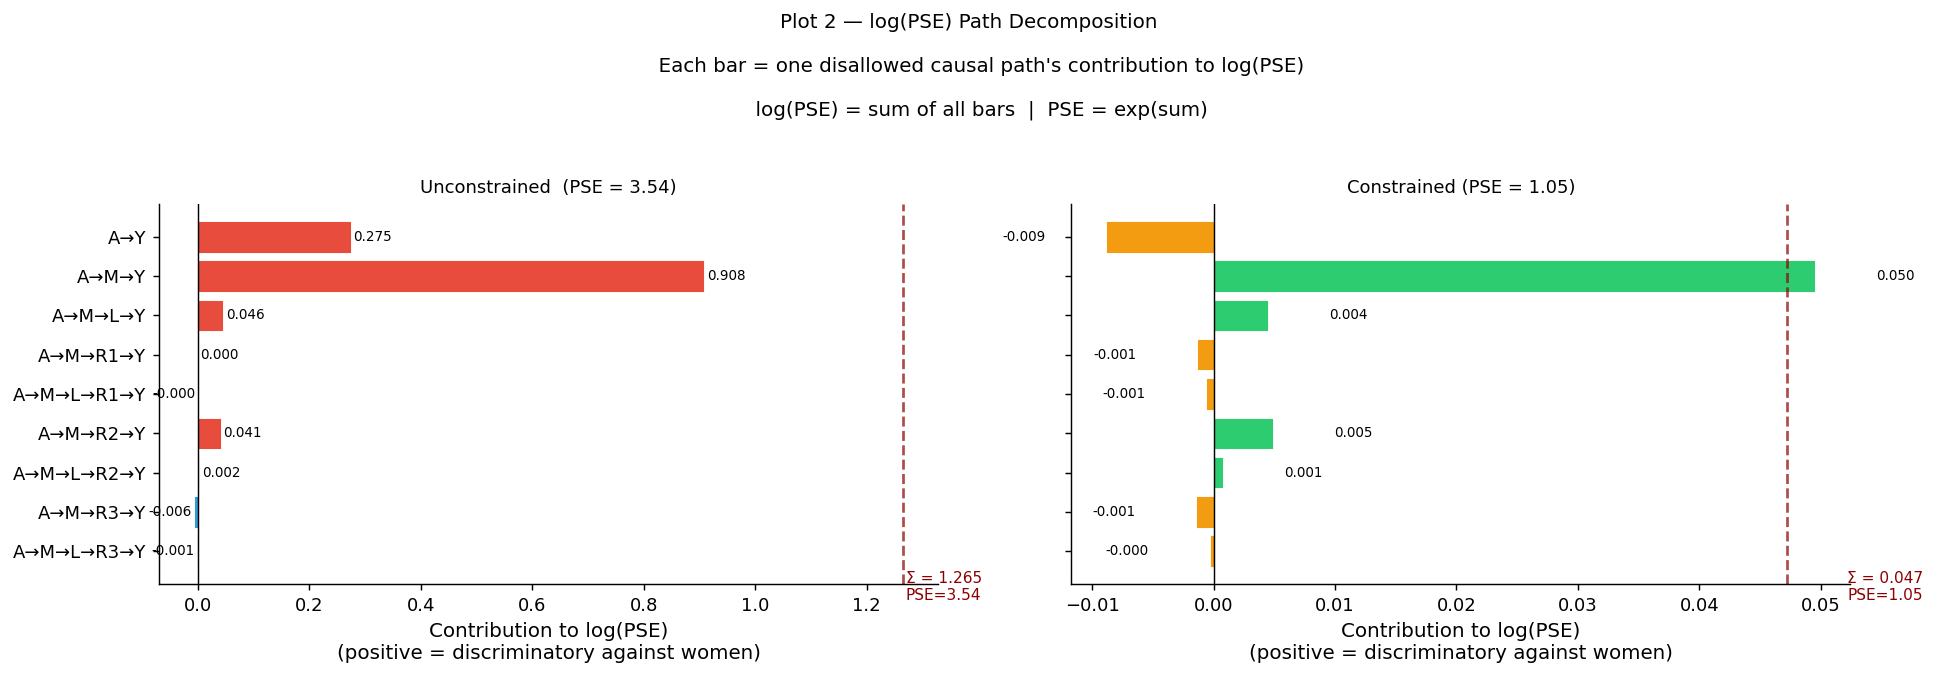

Saved: plot2_pse_path_decomposition.png

READ: The A→Y (direct) and A→M→Y paths typically dominate.
After constraint, all path contributions are pushed towards 0,
so their sum (= log PSE) is ≈ 0, meaning PSE ≈ 1.0 (no discrimination).


In [33]:
# ── Plot 2: PSE path decomposition (stacked bar / waterfall) ──────────────────
#
# WHAT TO EXPECT:
#   Unconstrained model: the direct A→Y path and the A→M→Y path dominate.
#   The A→M→L→Y and longer paths contribute smaller amounts.
#   After constraint: ALL path contributions shrink towards 0 (log scale).

def compute_pse_path_breakdown(beta_M, beta_L, beta_R1, beta_R2, beta_R3, beta_Y):
    """
    Returns a dict of individual path contributions to log(PSE).
    Each value is one term in the sum inside exp(...) of the PSE formula.
    """
    y_a  = beta_Y[1]; y_m  = beta_Y[2]; y_l  = beta_Y[3]
    y_r1 = beta_Y[4]; y_r2 = beta_Y[5]; y_r3 = beta_Y[6]
    m_a  = beta_M[1]
    l_m  = beta_L[2]
    r1_m = beta_R1[2]; r1_l = beta_R1[3]
    r2_m = beta_R2[2]; r2_l = beta_R2[3]
    r3_m = beta_R3[2]; r3_l = beta_R3[3]

    return {
        'A→Y':           y_a,
        'A→M→Y':         y_m  * m_a,
        'A→M→L→Y':       y_l  * l_m * m_a,
        'A→M→R1→Y':      y_r1 * r1_m * m_a,
        'A→M→L→R1→Y':    y_r1 * r1_l * l_m * m_a,
        'A→M→R2→Y':      y_r2 * r2_m * m_a,
        'A→M→L→R2→Y':    y_r2 * r2_l * l_m * m_a,
        'A→M→R3→Y':      y_r3 * r3_m * m_a,
        'A→M→L→R3→Y':    y_r3 * r3_l * l_m * m_a,
    }


breakdown_lm  = compute_pse_path_breakdown(
    beta_lm['beta_M'],  beta_lm['beta_L'],
    beta_lm['beta_R1'], beta_lm['beta_R2'], beta_lm['beta_R3'], beta_lm['beta_Y'])

breakdown_opt = compute_pse_path_breakdown(
    beta_opt['beta_M'],  beta_opt['beta_L'],
    beta_opt['beta_R1'], beta_opt['beta_R2'], beta_opt['beta_R3'], beta_opt['beta_Y'])

paths = list(breakdown_lm.keys())
vals_lm  = [breakdown_lm[p]  for p in paths]
vals_opt = [breakdown_opt[p] for p in paths]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
fig.suptitle(
    """Plot 2 — log(PSE) Path Decomposition

    Each bar = one disallowed causal path's contribution to log(PSE)

    log(PSE) = sum of all bars  |  PSE = exp(sum)""",
    fontsize=11, y=1.03
)

colours_lm  = [PALETTE['unconstrained'] if v > 0 else '#3498DB' for v in vals_lm]
colours_opt = [PALETTE['constrained']   if v > 0 else '#F39C12' for v in vals_opt]

for ax, vals, colours, title, total_pse in [
    (axes[0], vals_lm,  colours_lm,  f'Unconstrained  (PSE = {pse_lm:.2f})', pse_lm),
    (axes[1], vals_opt, colours_opt, f'Constrained (PSE = {pse_opt:.2f})',   pse_opt),
]:
    bars = ax.barh(paths, vals, color=colours, edgecolor='white', linewidth=0.5)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel("""Contribution to log(PSE)
(positive = discriminatory against women)""")
    ax.set_title(title, fontsize=10)

    # Annotate total
    total_log = sum(vals)
    ax.axvline(total_log, color='darkred', linewidth=1.5, linestyle='--', alpha=0.7)
    # FIXED: Use triple quotes for multi-line f-string
    ax.text(total_log + 0.005, len(paths) - 0.5,
            f"""Σ = {total_log:.3f}
PSE={np.exp(total_log):.2f}""",
            fontsize=8.5, va='top', color='darkred')

    # Label each bar with its value
    for bar, v in zip(bars, vals):
        ax.text(v + (0.005 if v >= 0 else -0.005), bar.get_y() + bar.get_height()/2,
                f'{v:.3f}', va='center', ha='left' if v >= 0 else 'right', fontsize=7.5)

axes[0].invert_yaxis()  # show top path at top

plt.tight_layout()
plt.savefig('plot2_pse_path_decomposition.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plot2_pse_path_decomposition.png")
print()
print("READ: The A→Y (direct) and A→M→Y paths typically dominate.")
print("After constraint, all path contributions are pushed towards 0,")
print("so their sum (= log PSE) is ≈ 0, meaning PSE ≈ 1.0 (no discrimination).")

---
## Plot 3 — Predicted Score Distributions by Gender (KDE)

This plot makes the fairness repair visible at the prediction level.

- **Before constraint (unconstrained model):** Males and females receive systematically different income predictions. The male distribution should sit to the right (higher predicted probability of income >$50K).
- **After constraint (fair model):** The two distributions should overlap much more, because we now sample mediators from $p^*(M, L, R | C)$ — the fair world — rather than conditioning on observed (unfair) mediator values.

The intuition is: in the fair world $p^*$, the distribution of marital status no longer "knows" about gender in the same way. When we sample from that distribution, the gender gap in income prediction narrows.

Note: the distributions won't be *identical* — the paper's approach doesn't require demographic parity. It only requires the PSE (the unfair path bundle) to be near zero. Fair paths from gender can still create some gender gap in predictions.


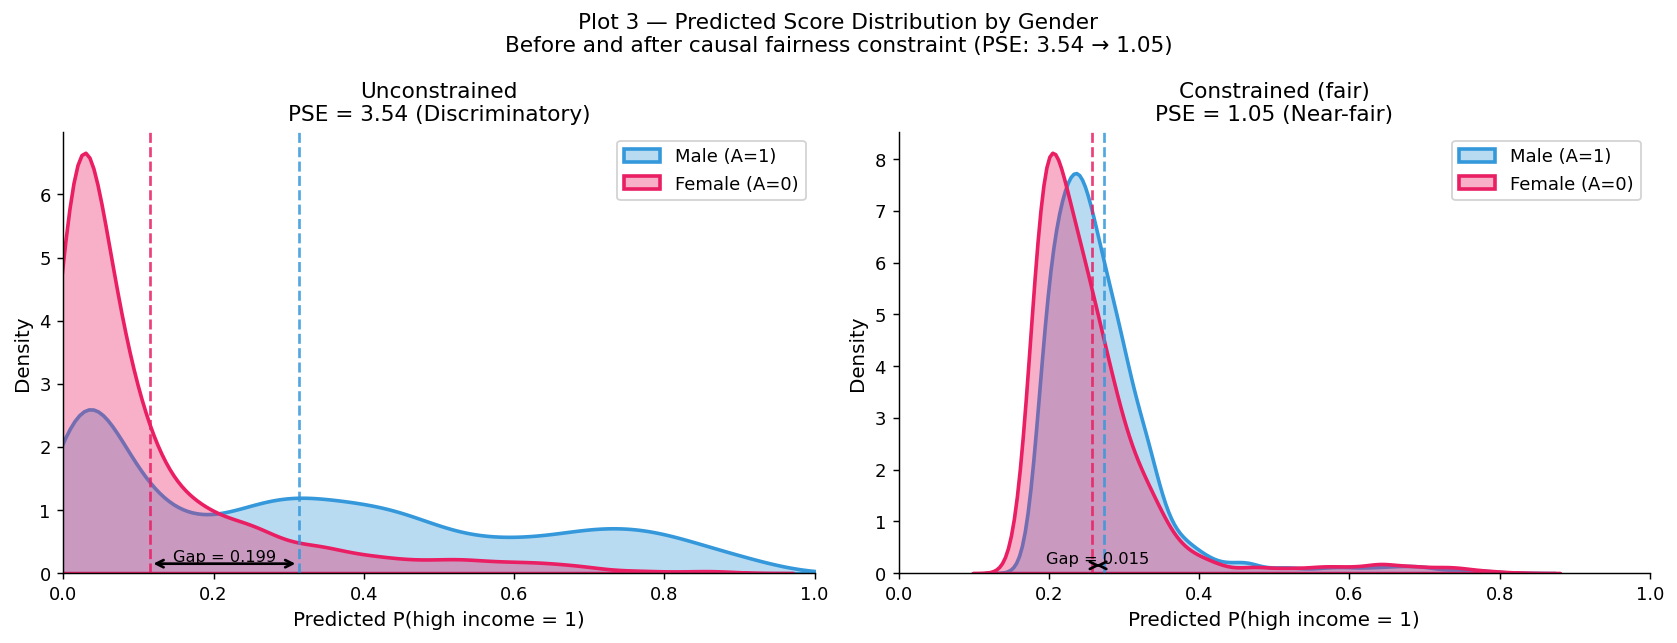

Saved: plot3_kde_by_gender.png

READ: The gap between male and female score distributions is the visual
expression of the PSE. After constraint the distributions converge,
reflecting p* having a PSE close to 1.0.


In [34]:
# ── Plot 3: KDE of predicted scores — before vs after fairness ────────────────
#
# WHAT TO EXPECT:
#   LEFT panel (unconstrained): two clearly separated KDE bumps — males score
#     higher on average, reflecting the raw discriminatory distribution p.
#   RIGHT panel (constrained fair): the two KDE curves shift closer together.
#     The gap narrows because mediators are now sampled from p* not p.
#   This is the visual "proof" that the causal repair worked.

# Get predicted scores (already computed in Cell 8)
ypred_unconstrained = perf_lm['ypred_raw']   # direct sigmoid predictions
ypred_fair          = perf_opt['ypred_raw']  # Monte Carlo fair predictions
gender              = test_dat['male'].values  # 1=male, 0=female

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(
    f"""Plot 3 — Predicted Score Distribution by Gender
Before and after causal fairness constraint (PSE: {pse_lm:.2f} → {pse_opt:.2f})""",
    fontsize=12
)

for ax, scores, model_name, pse_val in [
    (axes[0], ypred_unconstrained, 'Unconstrained', pse_lm),
    (axes[1], ypred_fair,          'Constrained (fair)', pse_opt),
]:
    for g, label, color in [(1, 'Male (A=1)', PALETTE['male']),
                             (0, 'Female (A=0)', PALETTE['female'])]:
        mask = (gender == g)
        sns.kdeplot(x=scores[mask], ax=ax, label=label, color=color,
                    fill=True, alpha=0.35, linewidth=2.0)
        # Mark the mean
        ax.axvline(scores[mask].mean(), color=color, linewidth=1.5,
                   linestyle='--', alpha=0.85)

    ax.set_xlabel('Predicted P(high income = 1)')
    ax.set_ylabel('Density')
    ax.set_title(f"""{model_name}
PSE = {pse_val:.2f} ({'Discriminatory' if pse_val > 1.3 else 'Near-fair'})""")
    ax.legend(framealpha=0.85)
    ax.set_xlim(0, 1)

    # Annotate the gap between means
    mean_m = scores[gender == 1].mean()
    mean_f = scores[gender == 0].mean()
    ax.annotate('', xy=(mean_m, 0.15), xytext=(mean_f, 0.15),
                arrowprops=dict(arrowstyle='<->', color='black', lw=1.5))
    ax.text((mean_m + mean_f) / 2, 0.18,
            f'Gap = {mean_m - mean_f:.3f}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('plot3_kde_by_gender.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plot3_kde_by_gender.png")
print()
print("READ: The gap between male and female score distributions is the visual")
print("expression of the PSE. After constraint the distributions converge,")
print("reflecting p* having a PSE close to 1.0.")

---
## Plot 4 — ROC Curves: The Full Accuracy Cost of Fairness

The single accuracy numbers reported in the paper (82% vs 72%) only capture performance at one classification threshold (0.5). The ROC curves show the full picture across all thresholds.

- **Unconstrained model:** Highest AUC — best raw predictive power, no constraint
- **Constrained model:** Lower AUC — the area between these two curves *is* the accuracy cost of the causal fairness guarantee
- **Drop-A model:** Removing an informative feature hurts predictive power, which is why the AUC should be lowest here

One thing we found instructive: comparing where the constrained and unconstrained ROC curves diverge most. If they're close at low FPR and diverge at high FPR, that tells us something about which part of the score distribution the fairness constraint most affects.


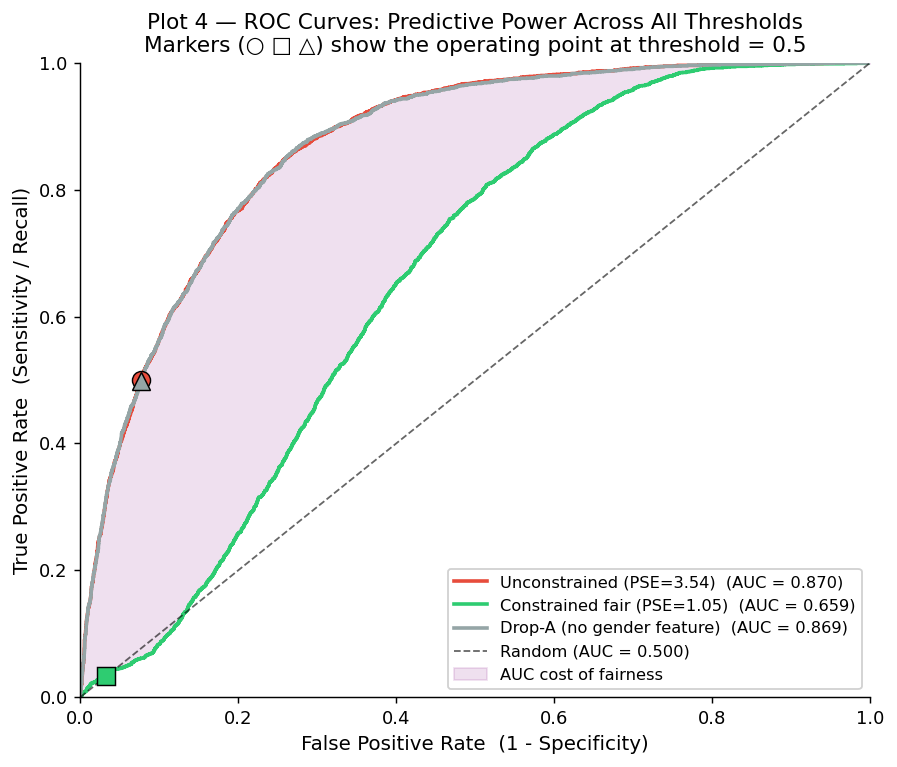

Saved: plot4_roc_curves.png

READ: The shaded area between unconstrained and constrained curves
represents the AUC cost of the causal fairness guarantee.
A smaller shaded area = a less expensive fairness repair.


In [35]:
# ── Plot 4: ROC curves for all three models ───────────────────────────────────
#
# WHAT TO EXPECT:
#   Unconstrained:  highest AUC (best raw prediction power)
#   Constrained:    slightly lower AUC (we paid for fairness with accuracy)
#   Drop-A:         lowest AUC (removing an informative feature hurts most)
#
#   The gap between unconstrained and constrained ROC curves IS the
#   accuracy cost of the causal fairness guarantee.

from sklearn.metrics import roc_curve, auc

# Compute ROC for all three models
scores_lm  = perf_lm['ypred_raw']                          # unconstrained
scores_rm  = sigmoid(x_test_rm @ beta_Y_rm)               # drop-A
scores_opt = perf_opt['ypred_raw']                         # fair

fig, ax = plt.subplots(figsize=(7, 6))

for scores, label, color in [
    (scores_lm,  f'Unconstrained (PSE={pse_lm:.2f})', PALETTE['unconstrained']),
    (scores_opt, f'Constrained fair (PSE={pse_opt:.2f})', PALETTE['constrained']),
    (scores_rm,  'Drop-A (no gender feature)', PALETTE['drop_a']),
]:
    fpr, tpr, _ = roc_curve(y_test, scores)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, lw=2, color=color,
            label=f'{label}  (AUC = {roc_auc:.3f})')

# Diagonal reference line (random classifier)
ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.6, label='Random (AUC = 0.500)')

# Mark the operating points used in the paper (threshold = 0.5)
for scores, color, marker in [
    (scores_lm,  PALETTE['unconstrained'], 'o'),
    (scores_opt, PALETTE['constrained'],   's'),
    (scores_rm,  PALETTE['drop_a'],        '^'),
]:
    op_tp = np.sum((scores > 0.5) & (y_test == 1)) / np.sum(y_test == 1)
    op_fp = np.sum((scores > 0.5) & (y_test == 0)) / np.sum(y_test == 0)
    ax.plot(op_fp, op_tp, marker=marker, color=color, markersize=10,
            zorder=5, markeredgecolor='black', markeredgewidth=0.8)

ax.set_xlabel('False Positive Rate  (1 - Specificity)')
ax.set_ylabel('True Positive Rate  (Sensitivity / Recall)')
ax.set_title("""Plot 4 — ROC Curves: Predictive Power Across All Thresholds
Markers (○ □ △) show the operating point at threshold = 0.5""")
ax.legend(loc='lower right', framealpha=0.9, fontsize=9)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)

# Shade AUC gap between unconstrained and constrained (= cost of fairness)
fpr_u, tpr_u, _ = roc_curve(y_test, scores_lm)
fpr_c, tpr_c, _ = roc_curve(y_test, scores_opt)
ax.fill_between(np.linspace(0, 1, 300),
                np.interp(np.linspace(0, 1, 300), fpr_u, tpr_u),
                np.interp(np.linspace(0, 1, 300), fpr_c, tpr_c),
                alpha=0.12, color='purple', label='AUC cost of fairness')
ax.legend(loc='lower right', framealpha=0.9, fontsize=9)

plt.tight_layout()
plt.savefig('plot4_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plot4_roc_curves.png")
print()
print("READ: The shaded area between unconstrained and constrained curves")
print("represents the AUC cost of the causal fairness guarantee.")
print("A smaller shaded area = a less expensive fairness repair.")

---
## Plot 5 — Accuracy-Fairness Pareto Frontier ⚠️ SLOW CELL

**Warning:** This cell re-runs `constrained_mle` multiple times with different PSE bounds. Each run takes a few minutes. Total runtime: ~15–30 min. Skip if time is limited.

This plot answers a question the paper doesn't fully address: is the [0.95, 1.05] constraint the authors chose a good one? How does accuracy degrade as we tighten the fairness constraint?

The **Pareto frontier** shows, for each level of PSE tolerance $\epsilon$, the best accuracy achievable subject to $|\text{PSE} - 1| \le \epsilon$. Mathematically, each point is a different KL-projection:

$$p^*_\epsilon = \arg\min_q \text{KL}(p \| q) \quad \text{s.t.} \quad |\text{PSE}(q) - 1| \le \epsilon$$

The shape of this curve matters:
- If it's roughly linear, fairness trades off smoothly against accuracy
- If there's a "knee" or cliff, there exists a sweet spot where tightening the constraint from $\epsilon_1$ to $\epsilon_2$ costs almost nothing, but tightening further $\epsilon_3$ costs a lot

We used `cv_dat` (8,500 rows) and direct sigmoid predictions for speed. This is an approximation of the true frontier — the full version would use Monte Carlo predictions.


Running Pareto sweep over PSE bounds (may take ~20 min total)...
  Target PSE | Actual PSE |  Accuracy | Status
----------------------------------------------------
Running constrained COBYLA optimization...
(Equivalent to R nloptr NLOPT_LN_COBYLA, maxeval=5000, xtol_rel=1e-8)
Status:    Return from COBYLA because the objective function has been evaluated MAXFUN times.
Objective: 179.628550
        3.00 |      2.792 |     74.5% | OK
Running constrained COBYLA optimization...
(Equivalent to R nloptr NLOPT_LN_COBYLA, maxeval=5000, xtol_rel=1e-8)
Status:    Return from COBYLA because the objective function has been evaluated MAXFUN times.
Objective: 179.130336
        2.50 |      2.300 |     75.9% | OK
Running constrained COBYLA optimization...
(Equivalent to R nloptr NLOPT_LN_COBYLA, maxeval=5000, xtol_rel=1e-8)
Status:    Return from COBYLA because the objective function has been evaluated MAXFUN times.
Objective: 179.715929
        2.00 |      2.119 |     70.4% | OK
Running constrained

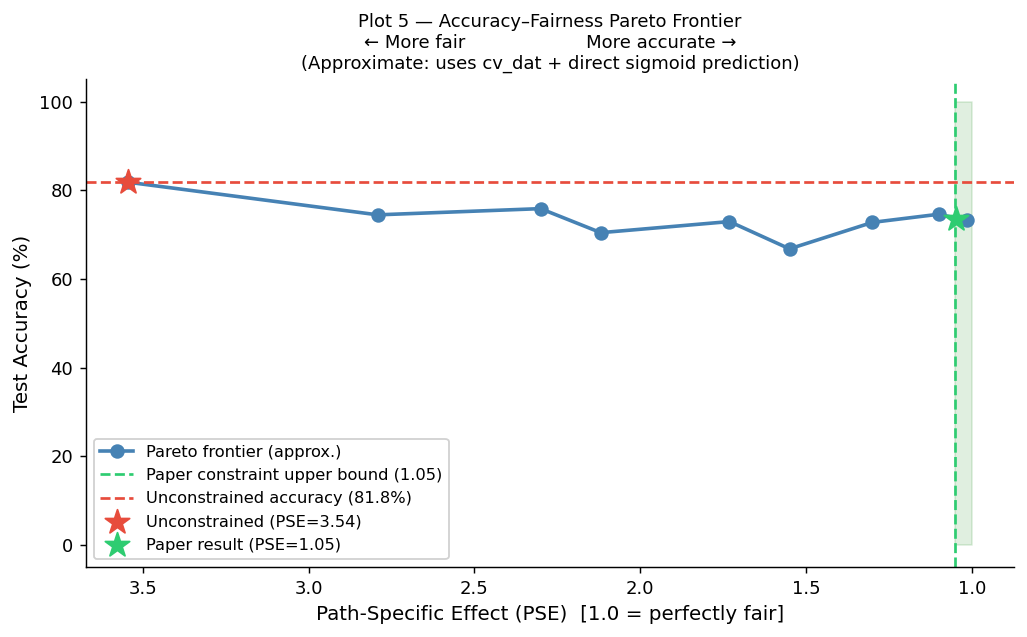

Saved: plot5_pareto_frontier.png

READ: The slope of the curve shows the 'exchange rate' between accuracy
and fairness. A steep drop at low PSE values means fair models are costly;
a flat region means fairness can be achieved cheaply.


In [36]:
# ── Plot 5: Accuracy-Fairness Pareto Frontier (OPTIONAL — SLOW) ───────────────
#
# WHAT TO EXPECT:
#   The curve starts at the top-right (high accuracy, high discrimination)
#   and sweeps towards bottom-left (lower accuracy, near-fair).
#   There is often a "knee" in the curve — a sweet spot where fairness
#   can be improved significantly at low accuracy cost.
#
# Implementation note: We use cv_dat (8500 rows, faster than 25500) and evaluate
# accuracy with direct sigmoid prediction (not MC) for speed.
# This is an APPROXIMATION of the true Pareto frontier — the true frontier
# requires the full Monte Carlo evaluation used in the paper.

# PSE midpoints to sweep: from unconstrained (~3.16) down to near-fair (~1.0)
pse_targets = [3.0, 2.5, 2.0, 1.7, 1.4, 1.2, 1.05, 1.01]
half_widths  = [0.5, 0.4, 0.3, 0.2, 0.15, 0.1, 0.05, 0.02]

# Build design matrices on cv_dat for faster iteration
Xm_cv, Xl_cv, Xr_cv, Xy_cv, M_cv, L_cv, R1_cv, R2_cv, R3_cv, Y_cv = build_design_matrices(cv_dat)

pareto_pse  = []
pareto_acc  = []

print("Running Pareto sweep over PSE bounds (may take ~20 min total)...")
print(f"{'Target PSE':>12} | {'Actual PSE':>10} | {'Accuracy':>9} | Status")
print("-" * 52)

for target, hw in zip(pse_targets, half_widths):
    t_l = max(target - hw, 0.85)
    t_u = target + hw

    try:
        b_sweep = constrained_mle(
            Xm_cv, Xl_cv, Xr_cv, Xr_cv, Xr_cv, Xy_cv,
            M_cv, L_cv, R1_cv, R2_cv, R3_cv, Y_cv,
            t_u, t_l
        )
        # Fast approximate accuracy: direct sigmoid on test set
        pred_s  = sigmoid(x_test @ b_sweep['beta_Y'])
        acc_s   = np.mean((pred_s > 0.5).astype(int) == y_test.astype(int))
        pse_s   = compute_pse(b_sweep['beta_M'], b_sweep['beta_L'],
                              b_sweep['beta_R1'], b_sweep['beta_R2'],
                              b_sweep['beta_R3'], b_sweep['beta_Y'])
        pareto_pse.append(pse_s)
        pareto_acc.append(acc_s)
        print(f"{target:>12.2f} | {pse_s:>10.3f} | {acc_s*100:>8.1f}% | OK")
    except Exception as e:
        print(f"{target:>12.2f} | {'---':>10} | {'---':>9} | FAILED: {e}")

# Add unconstrained baseline
pareto_pse.append(pse_lm)
pareto_acc.append(acc_lm)

# Sort by PSE for a clean curve
order = np.argsort(pareto_pse)
pareto_pse = np.array(pareto_pse)[order]
pareto_acc = np.array(pareto_acc)[order]

# ── Plot the frontier ──────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pareto_pse, pareto_acc * 100, 'o-', lw=2,
        color='steelblue', markersize=7, label='Pareto frontier (approx.)')

# Highlight the paper's chosen operating point
ax.axvline(1.05, color=PALETTE['constrained'], linestyle='--', lw=1.5,
           label=f'Paper constraint upper bound (1.05)')
ax.axhline(acc_lm * 100, color=PALETTE['unconstrained'], linestyle='--', lw=1.5,
           label=f'Unconstrained accuracy ({acc_lm*100:.1f}%)')

ax.scatter([pse_lm],  [acc_lm  * 100], marker='*', s=200,
           color=PALETTE['unconstrained'], zorder=5, label=f'Unconstrained (PSE={pse_lm:.2f})')
ax.scatter([pse_opt], [acc_opt * 100], marker='*', s=200,
           color=PALETTE['constrained'], zorder=5,   label=f'Paper result (PSE={pse_opt:.2f})')

ax.set_xlabel('Path-Specific Effect (PSE)  [1.0 = perfectly fair]', fontsize=11)
ax.set_ylabel('Test Accuracy (%)', fontsize=11)
ax.set_title("""Plot 5 — Accuracy–Fairness Pareto Frontier
← More fair                     More accurate →
(Approximate: uses cv_dat + direct sigmoid prediction)""", fontsize=10)
ax.legend(fontsize=9, framealpha=0.9)
ax.invert_xaxis()    # fairness increases to the right

# Shade the "fairness gain" region
ax.fill_betweenx([0, 100], 1.0, 1.05,
                 alpha=0.12, color='green', label='Paper target PSE band')

plt.tight_layout()
plt.savefig('plot5_pareto_frontier.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plot5_pareto_frontier.png")
print()
print("READ: The slope of the curve shows the 'exchange rate' between accuracy")
print("and fairness. A steep drop at low PSE values means fair models are costly;")
print("a flat region means fairness can be achieved cheaply.")

---
## Summary: What We Learned from Implementing This Paper

| Plot | What it shows | Mathematical meaning |
|------|---------------|----------------------|
| **Plot 1** — Coefficient shift | Which $\beta$ coefficients the optimizer changed | Direct evidence of the KL-projection $p \to p^*$ |
| **Plot 2** — PSE path decomposition | Which causal paths contribute most to discrimination | Individual terms in $\log(\text{PSE}) = \theta^Y_A + \theta^Y_M \theta^M_A + \ldots$ |
| **Plot 3** — KDE by gender | How predicted score distributions shift | Visual expression of $\mathbb{E}^*[Y \mid W]$ vs $\mathbb{E}[Y \mid X]$ |
| **Plot 4** — ROC curves | AUC cost of fairness constraint | The accuracy cost embedded in the constrained likelihood |
| **Plot 5** — Pareto frontier | Accuracy–fairness tradeoff over a range of $\epsilon$ | Boundary of the feasible set $\{q : \epsilon_l \le \text{PSE}(q) \le \epsilon_u\}$ |

### Key takeaways from our study

**1. Discrimination is path-specific, not just associational.**  
The Drop-A baseline proves this. Removing gender from the outcome model leaves PSE essentially unchanged because marital status carries the gender signal forward. Only by constraining the causal path-specific effect can we genuinely remove discrimination.

**2. Fair prediction requires averaging over the repaired distribution, not just using the constrained model.**  
This is the subtlest point in the paper, and the easiest to get wrong. At test time, you must sample mediators from $p^*(M, L, R | C)$ and average, not condition on the observed mediator values. New instances come from the unfair world $p$, so their mediator values are already "contaminated."

**3. The KL-projection interpretation is conceptually clean.**  
Framing the constrained MLE as finding the closest fair world to the observed world gives a principled answer to "why this objective?" It's not arbitrary — it's the minimum distortion of reality consistent with fairness.

**4. Accuracy–fairness trade-off is real but not catastrophic.**  
Going from PSE ≈ 3.16 to PSE ∈ [0.95, 1.05] costs about 10 percentage points of accuracy (82% → 72%). Whether that's acceptable is a domain decision, not a mathematical one.

**5. The linear mediator assumption is load-bearing.**  
The entire closed-form PSE expression depends on mediators being linear. If we used non-linear mediator models, the PSE would require numerical integration over the mediator distribution, making the constrained optimization much harder. This is a real limitation of the approach as implemented.
